In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
import httpx
import plotly.express as px
import plotly.io as pio
import unidecode
import seaborn as sns
import pyarrow as pa
import unicodedata

# Indice




# Ingesta de Datos

In [29]:
# df_bolsa_cereales_nacion = pd.read_excel("./../data/raw/datos_bolsa_cereales_nacion.csv") <-- DESCARTADO POR USAR ZONA PAS
df_bolsa_cereales_cba = pd.read_csv("./../data/raw/datos_bolsa_granos_cba.csv")
df_estimaciones_agricolas = pd.read_csv("./../data/raw/datos_estimaciones.csv",encoding="utf-8-sig")

# Preparacion de Indice de Cultivo

**NOTA**: Si bien los indices de cultivos al ser la proporción del rendimiento en grano respecto a la biomasa aérea total de la planta pueden variar por mejroas geneticas se suponen constantes y se utiliza los del paper como referencia

In [30]:
import pandas as pd

data = {
    "Cultivo": [
        "maíz", "soja", "trigo", "girasol", "maní", "garbanzo",
        "sorgo", "cebada", "centeno", "avena", "poroto",
        # Nuevos agregados
        "ajo",
        "colza",
        "papa",
        "lino",
        "arroz",
        "algodón"
    ],
    "IC": [
        0.47, 0.45, 0.35, 0.37, 0.40, 0.26,
        0.35, 0.53, 0.22, 0.35, 0.45,
        # Nuevos agregados
        0.55,   # ajo
        0.28,   # colza
        0.74,   # papa
        0.40,   # lino (valor representativo documentado)
        0.45,   # arroz (valor representativo del rango moderno)
        0.30    # algodón (lint HI representativo)
    ],
    "Fuente bibliográfica": [
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Bolsa de Cereales de Buenos Aires (2015)",
        "Raposo (2024)",
        "Haro (2022), Promedio variedad granoleico",
        "Promedio de lo obtenido por Apáez-Barrios (2017) y Ramacciotti (2015)",
        "Promedio de híbridos obtenido por Zamer y Chiarelli",
        "Cuda (2014)",
        "Zubiaga et al. (2023)",
        "Promedios obtenidos por Zubiaga et al. (2023)",
        "Ortega (2001)",
        # Nuevos agregados
        "Rizzalli, Villalobos & Orgaz (2002). European Journal of Agronomy",
        "Unkovich et al. / Advances in Agronomy (compilado ~2010); Lu et al. (2016)",
        "Xu et al. (análisis QUEFTS, Agronomy Journal); rango documentado 0.70-0.85",
        "Estudios de componentes de rendimiento (ADAS/AHDB y ensayos de monocultivo)",
        "Hay (1995) y estudios recientes de riego/N (rango moderno 0.40-0.55)",
        "Estudios regionales (Xinjiang y revisiones globales de lint HI)"
    ]
}

df_IC = pd.DataFrame(data)

df_IC['FR'] = (1 - df_IC['IC']) / df_IC['IC']

df_IC.head(20)

,Cultivo,IC,Fuente bibliográfica,FR
0,maíz,0.47,Bolsa de Cereales de Buenos Aires (2015),1.127660
1,soja,0.45,Bolsa de Cereales de Buenos Aires (2015),1.222222
2,trigo,0.35,Bolsa de Cereales de Buenos Aires (2015),1.857143
3,girasol,0.37,Raposo (2024),1.702703
4,maní,0.40,"Haro (2022), Promedio variedad granoleico",1.500000
5,garbanzo,0.26,Promedio de lo obtenido por Apáez-Barrios (201...,2.846154
6,sorgo,0.35,Promedio de híbridos obtenido por Zamer y Chia...,1.857143
7,cebada,0.53,Cuda (2014),0.886792
8,centeno,0.22,Zubiaga et al. (2023),3.545455
9,avena,0.35,Promedios obtenidos por Zubiaga et al. (2023),1.857143


### Markdown de aclaración (cultivos agregados + fuentes con links)

| Cultivo   | IC usado | Fuente y link |
|-----------|----------|---------------|
| **ajo**   | 0.55    | Rizzalli, R.H.; Villalobos, F.J.; Orgaz, F. (2002). *Radiation interception, radiation-use efficiency and dry matter partitioning in garlic (Allium sativum L.)*. European Journal of Agronomy 18(1-2): 33-43. HI reportado ≈0.55.<br>Link: https://www.sciencedirect.com/science/article/abs/pii/S1161030102000941<br>También respaldado por Escalante-Estrada et al. (2019) Terra Latinoamericana (IC ≈0.66–0.69 / 68%). |
| **colza** | 0.28    | Unkovich et al. (compilado en Advances in Agronomy) y Lu et al. (2016). Media ≈0.28 (rango documentado 0.04–0.42, típico 0.20–0.28).<br>Link de referencia: https://www.sciencedirect.com/science/article/abs/pii/S0378429016306840 y estudios de *Brassica napus* citados en PMC (ej. https://pmc.ncbi.nlm.nih.gov/articles/PMC6507709/). |
| **papa**  | 0.74    | Xu et al. (análisis QUEFTS en China, n=654). Media 0.74 (rango 0.40–0.95; 95% entre 0.52–0.87). Valores frecuentes 0.70–0.85 en literatura.<br>Link: https://acsess.onlinelibrary.wiley.com/doi/abs/10.2134/agronj2018.09.0572 |
| **lino**  | 0.40    | Valores documentados en ensayos de componentes de rendimiento (≈0.38) y monocultivos (hasta ≈0.51). Se usó 0.40 como representativo del rango reportado.<br>Referencias: estudios ADAS/AHDB y papers de *Linum usitatissimum* (ej. diversidad de HI en mezclas: https://pmc.ncbi.nlm.nih.gov/articles/PMC7611346/). |
| **arroz** | 0.45    | Rango moderno documentado 0.34–0.55 (frecuentemente 0.40–0.55; algunos ensayos ≥0.55–0.62). Se usó 0.45 como valor central representativo.<br>Fuente clásica: Hay (1995) Annals of Applied Biology + estudios recientes de riego/N. |
| **algodón** | 0.30  | Lint harvest index típico en regiones áridas ≈0.28–0.33 (Xinjiang); rangos globales más amplios. Se usó 0.30 como representativo.<br>Link: https://doi.org/10.3390/agronomy15030743 |

**Notas importantes:**
- No se agregaron cultivos sin dato confiable (alpiste, jojoba, yerba mate, tung, té, banana, cítricos, caña de azúcar, cebolla con IC estándar, etc.).
- Los valores de IC originales de la tabla se mantuvieron intactos.
- El cálculo de `FR` se aplica automáticamente a todos los registros (incluyendo los nuevos).

# Tratamiento de Datos

## Valores Nulos

In [31]:
print("================ BOLSA DE CEREALES CBA ================")
print(df_bolsa_cereales_cba.info())
print("================ MINISTERIO DE AGRICULTURA GANADERIA Y PESCA DE LA NACION ================")
print(df_estimaciones_agricolas.info())

================ BOLSA DE CEREALES CBA ================
<class 'pandas.DataFrame'>
RangeIndex: 4094 entries, 0 to 4093
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   PROVINCIA                        4094 non-null   str    
 1   DEPARTAMENTO                     4094 non-null   str    
 2   CULTIVO                          4094 non-null   str    
 3   CAMPAÑA                          4094 non-null   str    
 4   SEMBRADAS                        4094 non-null   float64
 5   COSECHADAS                       4094 non-null   float64
 6   RENDIMIENTO                      3850 non-null   float64
 7   RENDIMIENTO GRANO LIMPIO Y SECO  215 non-null    float64
 8   PRODUCCIÓN                       3850 non-null   float64
 9   PRODUCCIÓN GRANO LIMPIO Y SECO   215 non-null    float64
dtypes: float64(6), str(4)
memory usage: 448.7 KB
None
================ MINISTERIO DE AGRICULTURA GANADE

**NOTA**: Notamos que solo el dataset de la bolsa de cereales de cba tiene nulos, es por esto que vamos a proseguir solo con dicho dataset

### Visualizacion de Nulos

<Axes: >

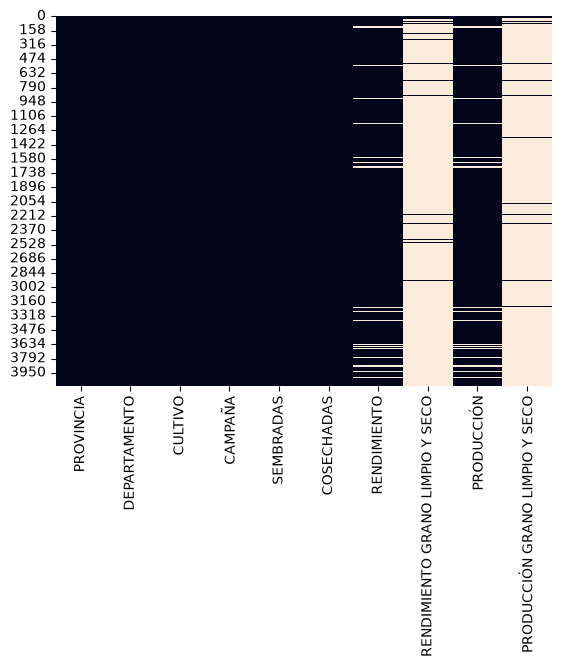

In [32]:
import seaborn as sns
sns.heatmap(df_bolsa_cereales_cba.isnull(), cbar=False)

**NOTA**: Observamos que debido a la falta de datos en columanas Limpio y Seco hay que desestimarlas (eliminarlas). Adicionalmente debemos notar que como el rendimiento es produccion sobre area entonces los nulos de rendimiento se dan cuando tengo nulos en Prouccion.

### Limpieza Dataset CBA

In [33]:
# Eliminamos Columnas Limpio y Seco

df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba.drop(columns=['RENDIMIENTO GRANO LIMPIO Y SECO','PRODUCCIÓN GRANO LIMPIO Y SECO'])

# Eliminamos filas con Nulos

df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba_cleaned.dropna()

print(df_bolsa_cereales_cba_cleaned.info())

<class 'pandas.DataFrame'>
Index: 3850 entries, 0 to 4093
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PROVINCIA     3850 non-null   str    
 1   DEPARTAMENTO  3850 non-null   str    
 2   CULTIVO       3850 non-null   str    
 3   CAMPAÑA       3850 non-null   str    
 4   SEMBRADAS     3850 non-null   float64
 5   COSECHADAS    3850 non-null   float64
 6   RENDIMIENTO   3850 non-null   float64
 7   PRODUCCIÓN    3850 non-null   float64
dtypes: float64(4), str(4)
memory usage: 393.5 KB
None


<Axes: >

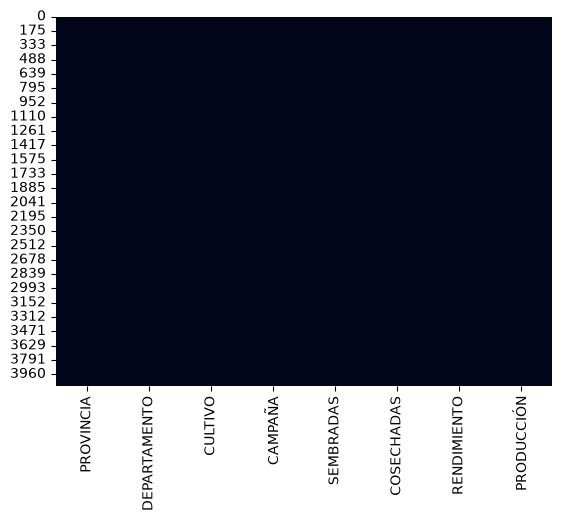

In [34]:
sns.heatmap(df_bolsa_cereales_cba_cleaned.isnull(), cbar=False)

## Limpieza de Columnas

### Cultivo

#### Taxonomía canónica de cultivos

In [35]:
# =================================================================
# CROP_TAXONOMY: fuente de verdad del dominio de cultivos MAGYP.
# Keys y canonical: en formato clean_str (minúsculas, sin acentos/ñ).
#
# Estructura:
#   canonical:      nombre canónico del cultivo
#   is_aggregate:   True si el registro es un "total" reportado por MAGYP
#   components:     lista de nombres raw (cleaned) que lo componen
#
# Reglas de negocio embebidas:
#  - "trigo candeal" (Triticum durum) NO se consolida con "trigo" (T. aestivum).
#  - "cana de azucar", "yerba mate": nombres compuestos, no se colapsan.
#  - Fail-fast: cualquier cultivo no listado genera error bloqueante.
# =================================================================

CROP_TAXONOMY = {
    # --- Familia soja ---
    "soja 1ra":   {"canonical": "soja",  "is_aggregate": False, "components": []},
    "soja 2da":   {"canonical": "soja",  "is_aggregate": False, "components": []},
    "soja total": {"canonical": "soja",  "is_aggregate": True,
                   "components": ["soja 1ra", "soja 2da"]},

    # --- Familia cebada ---
    "cebada cervecera": {"canonical": "cebada", "is_aggregate": False, "components": []},
    "cebada forrajera": {"canonical": "cebada", "is_aggregate": False, "components": []},
    "cebada total":     {"canonical": "cebada", "is_aggregate": True,
                         "components": ["cebada cervecera", "cebada forrajera"]},

    # --- Familia poroto ---
    "poroto alubia": {"canonical": "poroto", "is_aggregate": False, "components": []},
    "poroto negro":  {"canonical": "poroto", "is_aggregate": False, "components": []},
    "poroto otros":  {"canonical": "poroto", "is_aggregate": False, "components": []},
    "poroto total":  {"canonical": "poroto", "is_aggregate": True,
                      "components": ["poroto alubia", "poroto negro", "poroto otros"]},

    # --- Totales sin breakdown listado ---
    "trigo total":   {"canonical": "trigo",   "is_aggregate": True, "components": []},
    "papa total":    {"canonical": "papa",    "is_aggregate": True, "components": []},
    "cebolla total": {"canonical": "cebolla", "is_aggregate": True, "components": []},

    # --- Cultivos biológicamente/comercialmente distintos: NO merge ---
    "trigo candeal":  {"canonical": "trigo candeal",  "is_aggregate": False, "components": []},
    "cana de azucar": {"canonical": "cana de azucar", "is_aggregate": False, "components": []},
    "yerba mate":     {"canonical": "yerba mate",     "is_aggregate": False, "components": []},

    # --- Cultivos de nombre canónico único (identidad) ---
    "ajo":      {"canonical": "ajo",      "is_aggregate": False, "components": []},
    "algodon":  {"canonical": "algodon",  "is_aggregate": False, "components": []},
    "alpiste":  {"canonical": "alpiste",  "is_aggregate": False, "components": []},
    "arroz":    {"canonical": "arroz",    "is_aggregate": False, "components": []},
    "arveja":   {"canonical": "arveja",   "is_aggregate": False, "components": []},
    "avena":    {"canonical": "avena",    "is_aggregate": False, "components": []},
    "banana":   {"canonical": "banana",   "is_aggregate": False, "components": []},
    "cartamo":  {"canonical": "cartamo",  "is_aggregate": False, "components": []},
    "centeno":  {"canonical": "centeno",  "is_aggregate": False, "components": []},
    "colza":    {"canonical": "colza",    "is_aggregate": False, "components": []},
    "garbanzo": {"canonical": "garbanzo", "is_aggregate": False, "components": []},
    "girasol":  {"canonical": "girasol",  "is_aggregate": False, "components": []},
    "jojoba":   {"canonical": "jojoba",   "is_aggregate": False, "components": []},
    "lenteja":  {"canonical": "lenteja",  "is_aggregate": False, "components": []},
    "limon":    {"canonical": "limon",    "is_aggregate": False, "components": []},
    "lino":     {"canonical": "lino",     "is_aggregate": False, "components": []},
    "maiz":     {"canonical": "maiz",     "is_aggregate": False, "components": []},
    "mandarina":{"canonical": "mandarina","is_aggregate": False, "components": []},
    "mani":     {"canonical": "mani",     "is_aggregate": False, "components": []},
    "mijo":     {"canonical": "mijo",     "is_aggregate": False, "components": []},
    "naranja":  {"canonical": "naranja",  "is_aggregate": False, "components": []},
    "pomelo":   {"canonical": "pomelo",   "is_aggregate": False, "components": []},
    "sorgo":    {"canonical": "sorgo",    "is_aggregate": False, "components": []},
    "te":       {"canonical": "te",       "is_aggregate": False, "components": []},
    "tung":     {"canonical": "tung",     "is_aggregate": False, "components": []},
}

In [36]:
# NFKD descompone é → e + ´, y ñ → n + ˜
#.encode('ascii', 'ignore').decode('ascii') descarta los acentos/tilde que quedaron sueltos elimina acentos Y ñ 
#.strip().lower() → minúsculas sin espacios

def clean_str(s: str) -> str:
    s = unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode('ascii')
    return s.strip().lower()


#### Función de resolución

In [37]:
def resolve_crops(
    df: pd.DataFrame,
    taxonomy: dict,
    raw_col: str = "Cultivo",
    keys: tuple = ("Campaña", "Provincia", "Departamento"),
) -> pd.DataFrame:
    """
    Resuelve el problema de total vs componentes a nivel de clave (Campaña,
    Provincia, Departamento, cultivo_canónico).

    Regla: si el grupo tiene al menos un registro marcado como agregado,
    se conservan únicamente los agregados; en caso contrario, se conservan
    todos los componentes para que sean sumados por el groupby posterior.
    """
    df = df.copy()

    # Fallback: raw no mapeado -> identidad, marcado como no-agregado
    def lookup(c):
        entry = taxonomy.get(c)
        if entry is None:
            return pd.Series([c, False, True])  # último flag: is_unknown
        return pd.Series([entry["canonical"], entry["is_aggregate"], False])

    df[["_canonical", "_is_aggregate", "_is_unknown"]] = df[raw_col].apply(lookup)

    if df["_is_unknown"].any():
        unmapped = df.loc[df["_is_unknown"], raw_col].unique().tolist()
        raise ValueError(
            f"Cultivos sin mapeo en la taxonomía: {unmapped}. "
            "Agregar explícitamente antes de continuar."
        )

    gkey = list(keys) + ["_canonical"]
    df["_has_aggregate"] = df.groupby(gkey)["_is_aggregate"].transform("any")

    # Regla de resolución
    keep_mask = (~df["_has_aggregate"]) | (df["_is_aggregate"])
    resolved = df.loc[keep_mask].copy()

    # Trazabilidad: guardar de qué registro raw vino cada fila resuelta
    resolved["_source_cultivo"] = resolved[raw_col]
    resolved = resolved.rename(columns={"_canonical": "Cultivo"})
    resolved = resolved.drop(
        columns=[raw_col, "_is_aggregate", "_has_aggregate", "_is_unknown"]
    )
    return resolved

#### Tests

In [38]:
def test_no_duplicate_total_and_components():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 3,
        "Provincia": ["cordoba"] * 3,
        "Departamento": ["rio cuarto"] * 3,
        "Cultivo": ["soja 1ra", "soja 2da", "soja total"],
        "Producción": [1000, 500, 1500],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1
    assert out.iloc[0]["Cultivo"] == "soja"
    assert out.iloc[0]["_source_cultivo"] == "soja total"

def test_components_kept_when_no_total():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 2,
        "Provincia": ["cordoba"] * 2,
        "Departamento": ["rio cuarto"] * 2,
        "Cultivo": ["soja 1ra", "soja 2da"],
        "Producción": [1000, 500],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 2
    assert set(out["Cultivo"]) == {"soja"}

def test_trigo_candeal_not_merged_with_trigo():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 2,
        "Provincia": ["cordoba"] * 2,
        "Departamento": ["rio cuarto"] * 2,
        "Cultivo": ["trigo total", "trigo candeal"],
        "Producción": [10000, 2000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert set(out["Cultivo"]) == {"trigo", "trigo candeal"}
    assert len(out) == 2

def test_fails_on_unmapped_crop():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["x"], "Departamento": ["y"],
        "Cultivo": ["quinoa"], "Producción": [100],
    })
    with pytest.raises(ValueError, match="quinoa"):
        resolve_crops(df, CROP_TAXONOMY)

#### Documento de politica de consolidacion


POL-CROP-001: Consolidación de registros "X total" vs componentes

Alcance: dataset MAGYP Estimaciones Agrícolas.
Vigencia: desde <fecha>, versión <vX.Y>.

Regla 1 (jerarquía de agregación):
  Cuando para una clave (Campaña, Provincia, Departamento) existan
  simultáneamente un registro "X total" y registros "X <variante>",
  prevalece "X total". Los componentes se descartan para esa clave
  por riesgo de doble conteo.

Regla 2 (fallback):
  Cuando no exista "X total" para una clave, se conservan los
  componentes y se suman en la etapa de agregación.

Regla 3 (cultivos compuestos):
  Los cultivos cuyo nombre canónico contiene más de una palabra
  (caña de azúcar, yerba mate) NO se colapsan a la primera palabra.

Regla 4 (cultivos biológicamente distintos):
  Trigo candeal (Triticum durum) y trigo pan (Triticum aestivum)
  son cultivos distintos. NO se consolidan bajo "trigo".

Regla 5 (fail-fast):
  Todo cultivo no presente en la taxonomía canónica genera error
  bloqueante en el pipeline. No se permite fallback silencioso.

#### Texto con jerga técnica (para el notebook o la documentación)

Resolución determinística de agregados y componentes en la dimensión cultivo

El dataset de estimaciones agrícolas de MAGYP presenta, para algunas familias de cultivos, registros concurrentes bajo dos modalidades de reporte: (i) un registro agregado bajo la denominación <cultivo> total, y (ii) uno o más registros correspondientes a las variantes que componen dicho agregado (por ejemplo, soja 1ra, soja 2da; cebada cervecera, cebada forrajera; poroto alubia, poroto negro, poroto otros).

Una suma ingenua sobre la dimensión cultivo produce doble conteo, dado que el total y sus componentes coexisten en la tabla staging. Para resolverlo se implementa un mecanismo de resolución por prioridad jerárquica a nivel de clave natural (Campaña, Provincia, Departamento, cultivo_canónico):

Normalización canónica del nombre de cultivo mediante una tabla de mapeo declarativa (CROP_TAXONOMY) que asigna a cada nombre raw su nombre canónico, la marca booleana is_aggregate y la lista de componentes declarados. Los cultivos cuyo nombre canónico contiene más de una palabra (p. ej. caña de azúcar, yerba mate) o que representan especies biológicamente distintas (p. ej. trigo candeal vs trigo) se preservan como entidades independientes.

Detección de coexistencia agregado-componente por clave mediante groupby.transform("any") sobre la marca is_aggregate.

Selección por prioridad: en claves donde coexisten ambas modalidades, se conservan únicamente los registros agregados, descartando los componentes para evitar doble conteo. En claves donde sólo existen componentes, se conservan todos, delegando su suma a la etapa posterior de groupby.

Fail-fast ante cultivos no mapeados: todo nombre de cultivo ausente en la taxonomía canónica produce un error bloqueante. Se prohíbe explícitamente el silent fallback, que introduciría merges accidentales ante la incorporación de nuevos cultivos en futuras actualizaciones de la fuente.

La lógica se implementa como función pura (resolve_crops) con cobertura de tests de invariantes: (a) no duplicación por clave, (b) preservación de componentes ante ausencia de total, (c) separación de cultivos compuestos y biológicamente distintos, (d) falla ante entradas no mapeadas. Se preserva la trazabilidad mediante la columna _source_cultivo, que registra el nombre raw que originó cada registro resuelto, permitiendo reconstruir el linaje del dato en la capa curated.

#### Bolsa de Cereales de CBA

In [39]:
print(sorted(df_bolsa_cereales_cba_cleaned["CULTIVO"].unique()))

['GARBANZO', 'GIRASOL', 'MAIZ', 'MANI', 'SOJA', 'SORGO', 'SORGO ', 'TRIGO', 'TRIGO CANDEAL']


**NOTA**: Observamos que todos los valores estan em mayusculas ademas de que hay errores porque algunos de ellos incluyen un espacio asi que pasamos a dejarlos en minusculas y sin espacios innecesarios. Adicionalemnte eliminaremos acentos y ñ para que sea mas facil trbajar por temas de codificaciones.

In [40]:
df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba_cleaned.rename(columns={'CULTIVO':'Cultivo'})
# 1. Normalización
df_bolsa_cereales_cba_cleaned["Cultivo"] = df_bolsa_cereales_cba_cleaned["Cultivo"].apply(clean_str)

# 2. Resolución canónica + total/componentes
df_bolsa_cereales_cba_cleaned_cleaned = resolve_crops(
    df_bolsa_cereales_cba_cleaned,
    CROP_TAXONOMY,
)

print("Cultivos canónicos resultantes:")
print(sorted(df_bolsa_cereales_cba_cleaned_cleaned["Cultivo"].unique()))
print(f"\nRegistros antes: {len(df_bolsa_cereales_cba_cleaned):,}")
print(f"Registros después: {len(df_bolsa_cereales_cba_cleaned_cleaned):,}")

ValueError: Cultivos sin mapeo en la taxonomía: ['trigo', 'soja']. Agregar explícitamente antes de continuar.

##### Test

In [ ]:
import pytest
import pandas as pd

# Importar clean_str, CROP_TAXONOMY, resolve_crops desde el módulo correspondiente
from etl.transformers.crop_taxonomy import CROP_TAXONOMY
from etl.transformers.crop_consolidation import resolve_crops


def _df(cultivos, producciones):
    n = len(cultivos)
    return pd.DataFrame({
        "Campaña":      ["2020/21"] * n,
        "Provincia":    ["cordoba"] * n,
        "Departamento": ["rio cuarto"] * n,
        "Cultivo":      cultivos,
        "Producción":   producciones,
    })


def test_total_prevalece_sobre_componentes_soja():
    df = _df(["soja 1ra", "soja 2da", "soja total"], [1000, 500, 1500])
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1
    assert out.iloc[0]["Cultivo"] == "soja"
    assert out.iloc[0]["_source_cultivo"] == "soja total"
    assert out.iloc[0]["Producción"] == 1500


def test_componentes_se_conservan_sin_total():
    df = _df(["soja 1ra", "soja 2da"], [1000, 500])
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 2
    assert set(out["Cultivo"]) == {"soja"}


def test_trigo_candeal_no_se_consolida_con_trigo():
    df = _df(["trigo total", "trigo candeal"], [10000, 2000])
    out = resolve_crops(df, CROP_TAXONOMY)
    assert set(out["Cultivo"]) == {"trigo", "trigo candeal"}
    assert len(out) == 2


def test_cultivo_compuesto_no_se_colapsa():
    df = _df(["cana de azucar"], [5000])
    out = resolve_crops(df, CROP_TAXONOMY)
    assert out.iloc[0]["Cultivo"] == "cana de azucar"


def test_fail_fast_ante_cultivo_no_mapeado():
    df = _df(["quinoa"], [100])
    with pytest.raises(ValueError, match="quinoa"):
        resolve_crops(df, CROP_TAXONOMY)


def test_no_duplicados_por_clave():
    df = _df(["soja 1ra", "soja 2da", "soja total"], [1000, 500, 1500])
    out = resolve_crops(df, CROP_TAXONOMY)
    keys = ["Campaña", "Provincia", "Departamento", "Cultivo"]
    assert out.duplicated(keys).sum() == 0


def test_idempotencia_clean_str():
    from etl.transformers.string_utils import clean_str
    for s in ["  MAÍZ ", "Cebada  Cervecera", "TRIGO CANDEAL", "Caña de Azúcar"]:
        assert clean_str(clean_str(s)) == clean_str(s)

##### Analisis de Consistencia

In [ ]:
# =================================================================
# ANÁLISIS DE CONSISTENCIA: ¿el "total" reportado de la bolsa de CBA coincide
# con la suma de sus componentes declarados, a nivel de clave?
# =================================================================

df_diag = df_bolsa_cereales_cba_cleaned.copy()
df_diag["Cultivo"] = df_diag["Cultivo"].apply(clean_str)

# Mapear a canónico sin resolver todavía (queremos ver AMBOS lados)
meta = df_diag["Cultivo"].map(CROP_TAXONOMY)
df_diag["_canonical"]    = meta.map(lambda x: x["canonical"])
df_diag["_is_aggregate"] = meta.map(lambda x: x["is_aggregate"])

KEY = ["Campaña", "Provincia", "Departamento", "_canonical"]

# Suma de componentes vs valor del total, por clave
pivot = (
    df_diag
    .groupby(KEY + ["_is_aggregate"])["Producción"]
    .sum()
    .unstack("_is_aggregate")
    .rename(columns={False: "suma_componentes", True: "total_reportado"})
    .dropna()  # sólo claves donde coexisten ambos
)

# Diferencia relativa: (total_reportado - suma_componentes) / suma_componentes
pivot["diff_rel"] = (
    (pivot["total_reportado"] - pivot["suma_componentes"])
    / pivot["suma_componentes"].replace(0, pd.NA)
)

print(f"Claves con coexistencia total + componentes: {len(pivot):,}")
print("\nDistribución de diff_rel (total vs suma de componentes):")
print(pivot["diff_rel"].describe(percentiles=[.05, .25, .5, .75, .95]))

tolerancia = 0.05
inconsistentes = pivot[pivot["diff_rel"].abs() > tolerancia]
print(f"\nClaves con |diff_rel| > {tolerancia:.0%}: {len(inconsistentes):,} "
      f"({len(inconsistentes) / len(pivot):.2%})")

if len(inconsistentes) > 0:
    print("\nTop 10 discrepancias absolutas:")
    print(inconsistentes.reindex(
        inconsistentes["diff_rel"].abs().sort_values(ascending=False).index
    ).head(10))

##### Registro de Auditoria

In [ ]:
# Guardar evidencia de qué registros fueron descartados y por qué
df_pre_resolucion = df_bolsa_cereales_cba_cleaned.copy()
df_pre_resolucion["Cultivo"] = df_pre_resolucion["Cultivo"].apply(clean_str)

KEY_RES = ["Campaña", "Provincia", "Departamento", "Cultivo"]
claves_resueltas = df_bolsa_cereales_cba_cleaned_cleaned[KEY_RES].apply(tuple, axis=1)

df_audit_descartados = (
    df_pre_resolucion
    .assign(_key=df_pre_resolucion[KEY_RES].apply(tuple, axis=1))
    .loc[lambda d: ~d["_key"].isin(set(claves_resueltas))]
    .drop(columns="_key")
)

print(f"Registros descartados por política total>componentes: {len(df_audit_descartados):,}")
print("\nDetalle por cultivo original:")
print(df_audit_descartados["Cultivo"].value_counts())

# Persistir para auditoría
# df_audit_descartados.to_parquet("data/audit/descartados_resolucion_cultivos.parquet")

#### MAGYP (ESTIMACIONES AGRICOLAS)

In [ ]:
print(sorted(df_estimaciones_agricolas["Cultivo"].unique()))

['Ajo', 'Algodón', 'Alpiste', 'Arroz', 'Arveja', 'Avena', 'Banana', 'Caña de azúcar', 'Cebada cervecera', 'Cebada forrajera', 'Cebada total', 'Cebolla total', 'Centeno', 'Colza', 'Cártamo', 'Garbanzo', 'Girasol', 'Jojoba', 'Lenteja', 'Limón', 'Lino', 'Mandarina', 'Maní', 'Maíz', 'Mijo', 'Naranja', 'Papa total', 'Pomelo', 'Poroto alubia', 'Poroto negro', 'Poroto otros', 'Poroto total', 'Soja 1ra', 'Soja 2da', 'Soja total', 'Sorgo', 'Trigo candeal', 'Trigo total', 'Tung', 'Té', 'Yerba mate']


**NOTA**: Observamos que tiene capitalizacion tipo titulo ademas de acentos y ñ por lo que procedemos a limpiar de la misma manera que el dataset de bolsa de cereales de cba 

In [ ]:
# 1. Normalización
df_estimaciones_agricolas["Cultivo"] = df_estimaciones_agricolas["Cultivo"].apply(clean_str)

# 2. Resolución canónica + total/componentes
df_estimaciones_agricolas_cleaned = resolve_crops(
    df_estimaciones_agricolas,
    CROP_TAXONOMY,
)

print("Cultivos canónicos resultantes:")
print(sorted(df_estimaciones_agricolas_cleaned["Cultivo"].unique()))
print(f"\nRegistros antes: {len(df_estimaciones_agricolas):,}")
print(f"Registros después: {len(df_estimaciones_agricolas_cleaned):,}")

['ajo', 'algodon', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'cana de azucar', 'cartamo', 'cebada cervecera', 'cebada forrajera', 'cebada total', 'cebolla total', 'centeno', 'colza', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limon', 'lino', 'maiz', 'mandarina', 'mani', 'mijo', 'naranja', 'papa total', 'pomelo', 'poroto alubia', 'poroto negro', 'poroto otros', 'poroto total', 'soja 1ra', 'soja 2da', 'soja total', 'sorgo', 'te', 'trigo candeal', 'trigo total', 'tung', 'yerba mate']


**Nota metodológica**:  
Se identificó la presencia de cultivos registrados con la denominación TOTAL. Dichos registros representan la agregación de todas las variedades correspondientes a un mismo cultivo. Con el fin de evitar duplicaciones y asegurar la consistencia en el análisis, se decidió conservar únicamente aquellos cultivos que incluyen la denominación TOTAL. Los cultivos sin dicha denominación serán considerados únicamente en los casos en que no exista un registro equivalente con la categoría TOTAL para el mismo tipo de cultivo.

In [ ]:
# 1. Normalización
df_estimaciones_agricolas["Cultivo"] = df_estimaciones_agricolas["Cultivo"].apply(clean_str)

# 2. Resolución canónica + total/componentes
df_estimaciones_agricolas_cleaned = resolve_crops(
    df_estimaciones_agricolas,
    CROP_TAXONOMY,
)

print("Cultivos canónicos resultantes:")
print(sorted(df_estimaciones_agricolas_cleaned["Cultivo"].unique()))
print(f"\nRegistros antes: {len(df_estimaciones_agricolas):,}")
print(f"Registros después: {len(df_estimaciones_agricolas_cleaned):,}")

In [ ]:
# df = df_estimaciones_agricolas.copy()

# df["Cultivo_base"] = df["Cultivo"].str.replace(" total", "", regex=False)
# df["Es_total"] = df["Cultivo"].str.contains("total")

# df["Tiene_total"] = (
#     df.groupby(["Campaña", "Provincia", "Departamento", "Cultivo_base"])["Es_total"]
#       .transform("any")
# )

# df_filtrado = df[(~df["Tiene_total"]) | (df["Es_total"])]

# df_estimaciones_agricolas_cleaned = df_filtrado.rename( 
#   columns={
#     'Cultivo':'old_Cultivo',
#     'Cultivo_base':'Cultivo'
#   })

# print(sorted(df_estimaciones_agricolas_cleaned['Cultivo'].unique()))

['ajo', 'algodon', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'cana de azucar', 'cartamo', 'cebada', 'cebada cervecera', 'cebada forrajera', 'cebolla', 'centeno', 'colza', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limon', 'lino', 'maiz', 'mandarina', 'mani', 'mijo', 'naranja', 'papa', 'pomelo', 'poroto', 'poroto alubia', 'poroto negro', 'poroto otros', 'soja', 'soja 1ra', 'soja 2da', 'sorgo', 'te', 'trigo', 'trigo candeal', 'tung', 'yerba mate']


##### Test

In [ ]:
import pytest
import pandas as pd

# Importar clean_str, CROP_TAXONOMY, resolve_crops desde el módulo correspondiente
from etl.transformers.crop_taxonomy import CROP_TAXONOMY
from etl.transformers.crop_consolidation import resolve_crops


def _df(cultivos, producciones):
    n = len(cultivos)
    return pd.DataFrame({
        "Campaña":      ["2020/21"] * n,
        "Provincia":    ["cordoba"] * n,
        "Departamento": ["rio cuarto"] * n,
        "Cultivo":      cultivos,
        "Producción":   producciones,
    })


def test_total_prevalece_sobre_componentes_soja():
    df = _df(["soja 1ra", "soja 2da", "soja total"], [1000, 500, 1500])
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1
    assert out.iloc[0]["Cultivo"] == "soja"
    assert out.iloc[0]["_source_cultivo"] == "soja total"
    assert out.iloc[0]["Producción"] == 1500


def test_componentes_se_conservan_sin_total():
    df = _df(["soja 1ra", "soja 2da"], [1000, 500])
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 2
    assert set(out["Cultivo"]) == {"soja"}


def test_trigo_candeal_no_se_consolida_con_trigo():
    df = _df(["trigo total", "trigo candeal"], [10000, 2000])
    out = resolve_crops(df, CROP_TAXONOMY)
    assert set(out["Cultivo"]) == {"trigo", "trigo candeal"}
    assert len(out) == 2


def test_cultivo_compuesto_no_se_colapsa():
    df = _df(["cana de azucar"], [5000])
    out = resolve_crops(df, CROP_TAXONOMY)
    assert out.iloc[0]["Cultivo"] == "cana de azucar"


def test_fail_fast_ante_cultivo_no_mapeado():
    df = _df(["quinoa"], [100])
    with pytest.raises(ValueError, match="quinoa"):
        resolve_crops(df, CROP_TAXONOMY)


def test_no_duplicados_por_clave():
    df = _df(["soja 1ra", "soja 2da", "soja total"], [1000, 500, 1500])
    out = resolve_crops(df, CROP_TAXONOMY)
    keys = ["Campaña", "Provincia", "Departamento", "Cultivo"]
    assert out.duplicated(keys).sum() == 0


def test_idempotencia_clean_str():
    from etl.transformers.string_utils import clean_str
    for s in ["  MAÍZ ", "Cebada  Cervecera", "TRIGO CANDEAL", "Caña de Azúcar"]:
        assert clean_str(clean_str(s)) == clean_str(s)

##### Analisis de Consistencia

In [ ]:
# =================================================================
# ANÁLISIS DE CONSISTENCIA: ¿el "total" reportado por MAGYP coincide
# con la suma de sus componentes declarados, a nivel de clave?
# =================================================================

df_diag = df_estimaciones_agricolas.copy()
df_diag["Cultivo"] = df_diag["Cultivo"].apply(clean_str)

# Mapear a canónico sin resolver todavía (queremos ver AMBOS lados)
meta = df_diag["Cultivo"].map(CROP_TAXONOMY)
df_diag["_canonical"]    = meta.map(lambda x: x["canonical"])
df_diag["_is_aggregate"] = meta.map(lambda x: x["is_aggregate"])

KEY = ["Campaña", "Provincia", "Departamento", "_canonical"]

# Suma de componentes vs valor del total, por clave
pivot = (
    df_diag
    .groupby(KEY + ["_is_aggregate"])["Producción"]
    .sum()
    .unstack("_is_aggregate")
    .rename(columns={False: "suma_componentes", True: "total_reportado"})
    .dropna()  # sólo claves donde coexisten ambos
)

# Diferencia relativa: (total_reportado - suma_componentes) / suma_componentes
pivot["diff_rel"] = (
    (pivot["total_reportado"] - pivot["suma_componentes"])
    / pivot["suma_componentes"].replace(0, pd.NA)
)

print(f"Claves con coexistencia total + componentes: {len(pivot):,}")
print("\nDistribución de diff_rel (total vs suma de componentes):")
print(pivot["diff_rel"].describe(percentiles=[.05, .25, .5, .75, .95]))

tolerancia = 0.05
inconsistentes = pivot[pivot["diff_rel"].abs() > tolerancia]
print(f"\nClaves con |diff_rel| > {tolerancia:.0%}: {len(inconsistentes):,} "
      f"({len(inconsistentes) / len(pivot):.2%})")

if len(inconsistentes) > 0:
    print("\nTop 10 discrepancias absolutas:")
    print(inconsistentes.reindex(
        inconsistentes["diff_rel"].abs().sort_values(ascending=False).index
    ).head(10))

##### Registro de Auditoria

In [ ]:
# Guardar evidencia de qué registros fueron descartados y por qué
df_pre_resolucion = df_estimaciones_agricolas.copy()
df_pre_resolucion["Cultivo"] = df_pre_resolucion["Cultivo"].apply(clean_str)

KEY_RES = ["Campaña", "Provincia", "Departamento", "Cultivo"]
claves_resueltas = df_estimaciones_agricolas_cleaned[KEY_RES].apply(tuple, axis=1)

df_audit_descartados = (
    df_pre_resolucion
    .assign(_key=df_pre_resolucion[KEY_RES].apply(tuple, axis=1))
    .loc[lambda d: ~d["_key"].isin(set(claves_resueltas))]
    .drop(columns="_key")
)

print(f"Registros descartados por política total>componentes: {len(df_audit_descartados):,}")
print("\nDetalle por cultivo original:")
print(df_audit_descartados["Cultivo"].value_counts())

# Persistir para auditoría
# df_audit_descartados.to_parquet("data/audit/descartados_resolucion_cultivos.parquet")

### Capaña

vamos a utilizar el formato YYYY/YY como el formato estandar de nuestra columan campaña

In [ ]:
# Patrón correcto: 4 dígitos / 2 dígitos (ej. 2024/25)
pattern = r"^\d{4}/\d{2}$"

# Filtrar filas que NO cumplen el patrón
invalid_values_estimaciones = df_estimaciones_agricolas_cleaned.loc[~df_estimaciones_agricolas_cleaned["Campaña"].str.match(pattern, na=False), "Campaña"]
invalid_values_cba = df_bolsa_cereales_cba_cleaned.loc[~df_bolsa_cereales_cba_cleaned["CAMPAÑA"].str.match(pattern, na=False), "CAMPAÑA"]

print("Cantidad de valores fuera de formato YYYY/YY para Estimaciones Agricolas: ", len(invalid_values_estimaciones))
print("Cantidad de valores fuera de formato YYYY/YY para Bolsa de Cereales de CBA: ", len(invalid_values_cba))

Cantidad de valores fuera de formato YYYY/YY para Estimaciones Agricolas:  0
Cantidad de valores fuera de formato YYYY/YY para Bolsa de Cereales de CBA:  0


Observamos que todos los valores estan en formato.

### Provincia

#### Estimaciones Agricolas

In [ ]:
print(sorted(df_estimaciones_agricolas_cleaned["Provincia"].unique()))
print(len(df_estimaciones_agricolas_cleaned["Provincia"].unique()))

['BUENOS AIRES', 'CATAMARCA', 'CHACO', 'CHUBUT', 'CORDOBA', 'CORRIENTES', 'ENTRE RIOS', 'FORMOSA', 'JUJUY', 'LA PAMPA', 'LA RIOJA', 'MENDOZA', 'MISIONES', 'NEUQUEN', 'RIO NEGRO', 'SALTA', 'SAN JUAN', 'SAN LUIS', 'SANTA CRUZ', 'SANTA FE', 'SANTIAGO DEL ESTERO', 'TIERRA DEL FUEGO', 'TUCUMAN']
23


**NOTA**: Observamos que todas las provincias estan con capitalizacion ene mayuscula por lo que procedemso a escribirlas en minusculas sin acentos ni ñ.

In [ ]:
df_estimaciones_agricolas_cleaned['Provincia'] = df_estimaciones_agricolas_cleaned['Provincia'].apply(clean_str)
print(sorted(df_estimaciones_agricolas_cleaned["Provincia"].unique()))
print(len(df_estimaciones_agricolas_cleaned["Provincia"].unique()))

['buenos aires', 'catamarca', 'chaco', 'chubut', 'cordoba', 'corrientes', 'entre rios', 'formosa', 'jujuy', 'la pampa', 'la rioja', 'mendoza', 'misiones', 'neuquen', 'rio negro', 'salta', 'san juan', 'san luis', 'santa cruz', 'santa fe', 'santiago del estero', 'tierra del fuego', 'tucuman']
23


#### Bolsa de Cereales de Cordoba

In [ ]:
print(sorted(df_bolsa_cereales_cba_cleaned['PROVINCIA'].unique()))
print(len(df_bolsa_cereales_cba_cleaned['PROVINCIA'].unique()))

['Buenos Aires', 'Catamarca', 'Córdoba', 'La Pampa', 'San Luis', 'Santiago del Estero', 'Tucumán']
7


**NOTA**: observamos que la capitalicacion es de titulo y tienen caracteres que pueden causar problemas como los ascentos procedemos a sacarlos y cambiar capitalizacion a minuscula.

In [ ]:
df_bolsa_cereales_cba_cleaned['PROVINCIA'] = df_bolsa_cereales_cba_cleaned['PROVINCIA'].apply(clean_str)
print(sorted(df_bolsa_cereales_cba_cleaned["PROVINCIA"].unique()))
print(len(df_bolsa_cereales_cba_cleaned["PROVINCIA"].unique()))

['buenos aires', 'catamarca', 'cordoba', 'la pampa', 'san luis', 'santiago del estero', 'tucuman']
7


### Departamentos

#### Estimaciones Agricolas

In [ ]:
print(sorted(df_estimaciones_agricolas_cleaned["Departamento"].unique()))
print(len(df_estimaciones_agricolas_cleaned["Departamento"].unique()))

['1 DE MAYO', '12 DE OCTUBRE', '2 DE ABRIL', '25 DE MAYO', '25 de Mayo', '9 DE JULIO', 'ADOLFO ALSINA', 'ADOLFO GONZALES CHAVES', 'AGUIRRE', 'ALBARDON', 'ALBERDI', 'ALBERTI', 'ALMIRANTE BROWN', 'ALUMINE', 'AMBATO', 'ANCASTI', 'ANDALGALA', 'ANELO', 'ANGACO', 'ANTA', 'ANTOFAGASTA DE LA SIERRA', 'APOSTOLES', 'ARAUCO', 'ARRECIFES', 'ATAMISQUI', 'ATREUCO', 'AVELLANEDA', 'AYACUCHO', 'AZUL', 'BAHIA BLANCA', 'BALCARCE', 'BANDA', 'BARADERO', 'BARILOCHE', 'BELEN', 'BELGRANO', 'BELLA VISTA', 'BENITO JUAREZ', 'BERAZATEGUI', 'BERISSO', 'BERMEJO', 'BERON DE ASTRADA', 'BIEDMA', 'BOLIVAR', 'BRAGADO', 'BRANDSEN', 'BURRUYACU', 'CACHI', 'CAFAYATE', 'CAINGUAS', 'CALAMUCHITA', 'CALEU CALEU', 'CALINGASTA', 'CAMPANA', 'CANDELARIA', 'CANUELAS', 'CAPAYAN', 'CAPITAL', 'CAPITAN SARMIENTO', 'CARLOS CASARES', 'CARLOS TEJEDOR', 'CARMEN DE ARECO', 'CASEROS', 'CASTELLANOS', 'CASTELLI', 'CASTRO BARROS', 'CATRILO', 'CAUCETE', 'CERRILLOS', 'CHACABUCO', 'CHALILEO', 'CHAMICAL', 'CHAPALEUFU', 'CHASCOMUS', 'CHICLIGASTA', 'C

**Nota**: para asegurar la homogeneidad de los datos str en el dataset hacemos las mismas transformaciones que para provincias

In [ ]:
df_estimaciones_agricolas_cleaned['Departamento'] = df_estimaciones_agricolas_cleaned['Departamento'].apply(clean_str)
print(sorted(df_estimaciones_agricolas_cleaned["Departamento"].unique()))
print(len(df_estimaciones_agricolas_cleaned["Departamento"].unique()))

['1 de mayo', '12 de octubre', '2 de abril', '25 de mayo', '9 de julio', 'adolfo alsina', 'adolfo gonzales chaves', 'aguirre', 'albardon', 'alberdi', 'alberti', 'almirante brown', 'alumine', 'ambato', 'ancasti', 'andalgala', 'anelo', 'angaco', 'anta', 'antofagasta de la sierra', 'apostoles', 'arauco', 'arrecifes', 'atamisqui', 'atreuco', 'avellaneda', 'ayacucho', 'azul', 'bahia blanca', 'balcarce', 'banda', 'baradero', 'bariloche', 'belen', 'belgrano', 'bella vista', 'benito juarez', 'berazategui', 'berisso', 'bermejo', 'beron de astrada', 'biedma', 'bolivar', 'bragado', 'brandsen', 'burruyacu', 'cachi', 'cafayate', 'cainguas', 'calamuchita', 'caleu caleu', 'calingasta', 'campana', 'candelaria', 'canuelas', 'capayan', 'capital', 'capitan sarmiento', 'carlos casares', 'carlos tejedor', 'carmen de areco', 'caseros', 'castellanos', 'castelli', 'castro barros', 'catrilo', 'caucete', 'cerrillos', 'chacabuco', 'chalileo', 'chamical', 'chapaleufu', 'chascomus', 'chicligasta', 'chicoana', 'chi

#### Bolsa de Cereales de CBA

In [ ]:
print(sorted(df_bolsa_cereales_cba_cleaned["DEPARTAMENTO"].unique()))
print(len(df_bolsa_cereales_cba_cleaned["DEPARTAMENTO"].unique()))

['25 DE MAYO', '9 DE JULIO', 'ADOLFO ALSINA', 'AGUIRRE', 'ALBERDI', 'AMBATO', 'ATREUCO', 'AVELLANEDA', 'AYACUCHO', 'BANDA', 'BELGRANO', 'BOLIVAR', 'BURRUYACU', 'CALAMUCHITA', 'CAPITAL', 'CARLOS CASARES', 'CARLOS TEJEDOR', 'CATRILO', 'CHACABUCO', 'CHAPALEUFU', 'CHICLIGASTA', 'CHOYA', 'COLON', 'CONHELO', 'COPO', 'CORONEL PRINGLES', 'CRUZ ALTA', 'DAIREAUX', 'EL ALTO', 'FAMAILLA', 'FIGUEROA', 'FLORENTINO AMEGHINO', 'GENERAL PEDERNERA', 'GENERAL PINTO', 'GENERAL ROCA', 'GENERAL SAN MARTIN', 'GENERAL TABOADA', 'GENERAL VILLEGAS', 'GOBERNADOR DUPUY', 'GRAL ARENALES', 'GRAL PEDERNERA', 'GRAL VIAMONTE', 'GRAL. SAN MARTIN', 'GRANEROS', 'GUAMINI', 'GUASAYAN', 'GUATRACHE', 'HIPOLITO YRIGOYEN', 'HUCAL', 'ISCHILIN', 'Ischilin', 'J.B.ALBERDI', 'JIMENEZ', 'JUAN FELIPE IBARRA', 'JUAN MARTIN DE PUEYRREDON', 'JUAREZ CELMAN', 'JUNIN', 'LA COCHA', 'LA PAZ', 'LEALES', 'LEANDRO N ALEM', 'LIBERTADOR SAN MARTIN', 'LINCOLN', 'LOVENTUE', 'LULES', 'MARACO', 'MARCOS JUAREZ', 'MITRE', 'MONTEROS', 'MORENO', 'OJO DE 

**Nota**: para asegurar la homogeneidad de los datos str en el dataset hacemos las mismas transformaciones que para provincias

In [ ]:
df_bolsa_cereales_cba_cleaned['DEPARTAMENTO'] = df_bolsa_cereales_cba_cleaned['DEPARTAMENTO'].apply(clean_str)
print(sorted(df_bolsa_cereales_cba_cleaned["DEPARTAMENTO"].unique()))
print(len(df_bolsa_cereales_cba_cleaned["DEPARTAMENTO"].unique()))

['25 de mayo', '9 de julio', 'adolfo alsina', 'aguirre', 'alberdi', 'ambato', 'atreuco', 'avellaneda', 'ayacucho', 'banda', 'belgrano', 'bolivar', 'burruyacu', 'calamuchita', 'capital', 'carlos casares', 'carlos tejedor', 'catrilo', 'chacabuco', 'chapaleufu', 'chicligasta', 'choya', 'colon', 'conhelo', 'copo', 'coronel pringles', 'cruz alta', 'daireaux', 'el alto', 'famailla', 'figueroa', 'florentino ameghino', 'general pedernera', 'general pinto', 'general roca', 'general san martin', 'general taboada', 'general villegas', 'gobernador dupuy', 'gral arenales', 'gral pedernera', 'gral viamonte', 'gral. san martin', 'graneros', 'guamini', 'guasayan', 'guatrache', 'hipolito yrigoyen', 'hucal', 'ischilin', 'j.b.alberdi', 'jimenez', 'juan felipe ibarra', 'juan martin de pueyrredon', 'juarez celman', 'junin', 'la cocha', 'la paz', 'leales', 'leandro n alem', 'libertador san martin', 'lincoln', 'loventue', 'lules', 'maraco', 'marcos juarez', 'mitre', 'monteros', 'moreno', 'ojo de agua', 'pacl

## Unificamos Unidades

### Estimaciones

In [ ]:
df_estimaciones_agricolas_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 162041 entries, 0 to 162040
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   old_Cultivo     162041 non-null  str  
 1   Campaña         162041 non-null  str  
 2   Provincia       162041 non-null  str  
 3   Departamento    162041 non-null  str  
 4   idProvincia     162041 non-null  int64
 5   idDepartamento  162041 non-null  int64
 6   Sup. Sembrada   162041 non-null  str  
 7   Sup. Cosechada  162041 non-null  str  
 8   Producción      162041 non-null  str  
 9   Rendimiento     162041 non-null  str  
 10  Cultivo         162041 non-null  str  
 11  Es_total        162041 non-null  bool 
 12  Tiene_total     162041 non-null  bool 
dtypes: bool(2), int64(2), str(9)
memory usage: 22.4 MB


todos los campos numericos (Sup. Cosechada, Producción, Rendimiento, Cultivo_base) deben convertirse de strign a numero

In [ ]:
cols = ["Sup. Sembrada","Sup. Cosechada", "Producción", "Rendimiento"]
df_estimaciones_agricolas_cleaned[cols] = df_estimaciones_agricolas_cleaned[cols].apply(pd.to_numeric,errors='coerce')
df_estimaciones_agricolas_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 162041 entries, 0 to 162040
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   old_Cultivo     162041 non-null  str    
 1   Campaña         162041 non-null  str    
 2   Provincia       162041 non-null  str    
 3   Departamento    162041 non-null  str    
 4   idProvincia     162041 non-null  int64  
 5   idDepartamento  162041 non-null  int64  
 6   Sup. Sembrada   158840 non-null  float64
 7   Sup. Cosechada  158827 non-null  float64
 8   Producción      162024 non-null  float64
 9   Rendimiento     158823 non-null  float64
 10  Cultivo         162041 non-null  str    
 11  Es_total        162041 non-null  bool   
 12  Tiene_total     162041 non-null  bool   
dtypes: bool(2), float64(4), int64(2), str(5)
memory usage: 20.2 MB


In [ ]:
df_estimaciones_agricolas_cleaned.dropna(inplace=True)
df_estimaciones_agricolas_cleaned.info()

<class 'pandas.DataFrame'>
Index: 158823 entries, 0 to 162040
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   old_Cultivo     158823 non-null  str    
 1   Campaña         158823 non-null  str    
 2   Provincia       158823 non-null  str    
 3   Departamento    158823 non-null  str    
 4   idProvincia     158823 non-null  int64  
 5   idDepartamento  158823 non-null  int64  
 6   Sup. Sembrada   158823 non-null  float64
 7   Sup. Cosechada  158823 non-null  float64
 8   Producción      158823 non-null  float64
 9   Rendimiento     158823 non-null  float64
 10  Cultivo         158823 non-null  str    
 11  Es_total        158823 non-null  bool   
 12  Tiene_total     158823 non-null  bool   
dtypes: bool(2), float64(4), int64(2), str(5)
memory usage: 21.1 MB


### Bolsa de Cereales de CBA

In [ ]:
df_bolsa_cereales_cba_cleaned.info()

<class 'pandas.DataFrame'>
Index: 3850 entries, 0 to 4093
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PROVINCIA     3850 non-null   str    
 1   DEPARTAMENTO  3850 non-null   str    
 2   CULTIVO       3850 non-null   str    
 3   CAMPAÑA       3850 non-null   str    
 4   SEMBRADAS     3850 non-null   float64
 5   COSECHADAS    3850 non-null   float64
 6   RENDIMIENTO   3850 non-null   float64
 7   PRODUCCIÓN    3850 non-null   float64
dtypes: float64(4), str(4)
memory usage: 389.7 KB


No necesita cambios de tipso de variables

## Unificamos Dataframes

Para unificar debemos :
1. Definir que columnas de ambos DF dejamos : campaña, provincia, departamento, cultivo, superficie, produccion, rendimiento
2. agrupar cada dataframe por cultivo, provincia, departamento, cultivo, sumando superficie para obtener la total, sumando la produccion para obtener la total, recalcular el rendimiento
3. Unificar Unidades

### Agrupamos Dataframes

#### Estimaciones Agricolas

In [ ]:
df_est_agri_cleaned_grouped = (
    df_estimaciones_agricolas_cleaned
    .groupby(["Campaña", "Provincia", "Departamento", "Cultivo"], as_index=False)
    .agg({
        "Sup. Cosechada": "sum",
        "Producción": "sum"
    })
)

# Recalcular rendimiento como Producción / Superficie
df_est_agri_cleaned_grouped["Rendimiento (Tn/Ha)"] = df_est_agri_cleaned_grouped["Producción"] / df_est_agri_cleaned_grouped["Sup. Cosechada"]
df_est_agri_cleaned_grouped.head()


,Campaña,Provincia,Departamento,Cultivo,Sup. Cosechada,Producción,Rendimiento (Tn/Ha)
0,1969/70,buenos aires,25 de mayo,ajo,3.0,10.0,3.333333
1,1969/70,buenos aires,25 de mayo,alpiste,400.0,240.0,0.600000
2,1969/70,buenos aires,25 de mayo,avena,3000.0,4200.0,1.400000
3,1969/70,buenos aires,25 de mayo,cebada cervecera,2500.0,4750.0,1.900000
4,1969/70,buenos aires,25 de mayo,cebada forrajera,100.0,170.0,1.700000


#### Bolsa de Cereales CBA

In [ ]:
df_cba_cleaned_grouped = df_bolsa_cereales_cba_cleaned.groupby(["CAMPAÑA", "PROVINCIA", "DEPARTAMENTO", "CULTIVO"], as_index=False).agg({
        "SEMBRADAS": "sum",
        "COSECHADAS": "sum",
        "PRODUCCIÓN": "sum"
    })
df_cba_cleaned_grouped["RENDIMIENTO(Tn/Ha)"] = df_cba_cleaned_grouped["PRODUCCIÓN"] / df_cba_cleaned_grouped["COSECHADAS"]
df_cba_cleaned_grouped.head()

,CAMPAÑA,PROVINCIA,DEPARTAMENTO,CULTIVO,SEMBRADAS,COSECHADAS,PRODUCCIÓN,RENDIMIENTO(Tn/Ha)
0,2007/08,cordoba,colon,trigo,24741.0,24657.0,69038.0,2.799935
1,2007/08,cordoba,general roca,trigo,67668.0,67437.0,222543.0,3.300013
2,2007/08,cordoba,general san martin,trigo,67460.0,67230.0,228584.0,3.400030
3,2007/08,cordoba,juarez celman,trigo,89740.0,89435.0,330908.0,3.699983
4,2007/08,cordoba,marcos juarez,trigo,74392.0,74138.0,303966.0,4.100003


### Normalizmos Columnas

In [ ]:
# --- Normalización de df_cba_cleaned_grouped ---
df_cba_norm = df_cba_cleaned_grouped.rename(
    columns={
        "CAMPAÑA": "Campaña",
        "PROVINCIA": "Provincia",
        "DEPARTAMENTO": "Departamento",
        "CULTIVO": "Cultivo",
        "COSECHADAS": "Superficie (Ha)",
        "PRODUCCIÓN": "Produccion (Tn)",
        "RENDIMIENTO(Tn/Ha)": "Rendimiento (Tn/Ha)"
    }
)[["Provincia", "Departamento", "Campaña", "Cultivo", "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]]

# --- Normalización de df_est_agri_cleaned_grouped ---
df_est_norm = df_est_agri_cleaned_grouped.rename(
    columns={
        "Provincia": "Provincia",
        "Departamento": "Departamento",
        "Campaña": "Campaña",
        "Cultivo": "Cultivo",
        "Sup. Cosechada": "Superficie (Ha)",
        "Producción": "Produccion (Tn)",
        "Rendimiento (Tn/Ha)": "Rendimiento (Tn/Ha)"
    }
)[["Provincia", "Departamento", "Campaña", "Cultivo", "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]]



### Normalizamos columnas

In [ ]:
# Al construir df_cba_norm
df_cba_norm["fuente"] = "bolsa_cereales_cba"
df_cba_norm["source_file"] = "datos_bolsa_granos_cba.csv"
df_cba_norm["ingested_at"] = pd.Timestamp.utcnow()

# Al construir df_est_norm
df_est_norm["fuente"] = "magyp_estimaciones"
df_est_norm["source_file"] = "datos_estimaciones.csv"
df_est_norm["ingested_at"] = pd.Timestamp.utcnow()

C:\Users\Usuario\AppData\Local\Temp\ipykernel_11584\2888380282.py:4: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  df_cba_norm["ingested_at"] = pd.Timestamp.utcnow()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_11584\2888380282.py:9: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  df_est_norm["ingested_at"] = pd.Timestamp.utcnow()


### Concatenacion sin deduplicacion para auditoria

In [ ]:
KEY = ["Provincia", "Departamento", "Campaña", "Cultivo"]

# --- Concatenación ---
df_all = pd.concat([df_cba_norm, df_est_norm], ignore_index=True)

### Diagnostico por Solapamiento

In [ ]:
# ¿Cuántas celdas están en una, en ambas, en ninguna?
coverage = (
    df_all.groupby(KEY)["fuente"]
    .nunique()
    .value_counts()
    .rename_axis("n_fuentes")
    .to_frame("n_celdas")
)
print(coverage)
# n_fuentes  n_celdas
# 1          XXXX     (solo una fuente)
# 2          YYYY     (solapamiento)

           n_celdas
n_fuentes          
1            156201
2              3221


### Cuantificar la discrepancia en solapamientos

In [ ]:
solapadas = df_all[df_all.duplicated(KEY, keep=False)]

# Pivot para comparar por celda
cmp = solapadas.pivot_table(
    index=KEY,
    columns="fuente",
    values=["Superficie (Ha)", "Produccion (Tn)"],
    aggfunc="sum",
)

# Diferencia relativa: (MAGYP - Bolsa) / Bolsa
for var in ["Superficie (Ha)", "Produccion (Tn)"]:
    cmp[(var, "diff_rel")] = (
        (cmp[(var, "magyp_estimaciones")] - cmp[(var, "bolsa_cereales_cba")])
        / cmp[(var, "bolsa_cereales_cba")].replace(0, pd.NA)
    )

# Estadísticos clave
resumen = cmp.xs("diff_rel", axis=1, level=1).describe().T
print(resumen)
#               count   mean   std   min   25%   50%   75%   max
# Superficie     ...    ...    ...   ...   ...   ...   ...   ...
# Produccion     ...    ...    ...   ...   ...   ...   ...   ...

                  count  unique  top  freq
Superficie (Ha)  3216.0  3193.0 -1.0  12.0
Produccion (Tn)  3216.0  3199.0 -1.0  17.0


### Politica de Resolucion por prioridad

Criterio de resolución de duplicidades

Para la consolidación de los conjuntos de datos provenientes de distintas fuentes, se estableció un criterio de selección basado en la magnitud de la producción registrada. En particular, para cada combinación única de Provincia, Departamento, Campaña y Cultivo, se identificaron los registros duplicados y se seleccionó aquel que presentó el mayor valor de Producción (Tn).

Este procedimiento reemplaza un esquema de prioridad basado en la procedencia de los datos. Por lo tanto, la selección del registro no depende de que este provenga de una fuente considerada jerárquicamente superior, sino de un criterio cuantitativo aplicado de manera uniforme a todas las fuentes.

La utilización de la producción como variable de decisión permite conservar, ante discrepancias entre fuentes, el registro que representa el mayor volumen productivo informado para una misma unidad espacial, temporal y productiva. De esta manera, se evita introducir de forma exógena una preferencia institucional por una determinada fuente y se adopta una regla reproducible basada directamente en la variable de interés.

Asimismo, los registros que participan de una duplicidad son conservados temporalmente para fines de auditoría y trazabilidad. Una vez realizada la comparación, el registro con mayor producción es identificado como seleccionado, mientras que los restantes son clasificados como descartados. Esto permite reconstruir posteriormente las decisiones tomadas durante el proceso de integración de los datos y analizar las discrepancias existentes entre las fuentes originales.

In [ ]:
# =====================================================
# Consolidación de datasets
# Criterio de selección: mayor producción
# =====================================================

# Clave de identificación de un registro
KEY = [
    "Provincia",
    "Departamento",
    "Campaña",
    "Cultivo",
]

# =====================================================
# 1. Identificar registros duplicados
# =====================================================

# Se conservan temporalmente todos los registros que
# comparten la misma clave, independientemente de la fuente.
df_duplicados = df_all[
    df_all.duplicated(subset=KEY, keep=False)
].copy()


# =====================================================
# 2. Ordenar por producción descendente
# =====================================================

# Para cada combinación Provincia + Departamento +
# Campaña + Cultivo, el registro con mayor producción
# queda primero.
df_all = df_all.sort_values(
    KEY + ["Produccion (Tn)"],
    ascending=[True, True, True, True, False],
).copy()


# =====================================================
# 3. Seleccionar el registro con mayor producción
# =====================================================

# Si existen varios registros para la misma clave,
# se conserva únicamente el que presenta la mayor
# producción.
df_final = (
    df_all
    .drop_duplicates(
        subset=KEY,
        keep="first"
    )
    .reset_index(drop=True)
)


# =====================================================
# 4. Generar dataset de auditoría
# =====================================================

# Se vuelven a ordenar los duplicados por producción
# para poder identificar explícitamente cuál registro
# fue seleccionado y cuál fue descartado.

df_descartado = df_duplicados.copy()

df_descartado = df_descartado.sort_values(
    KEY + ["Produccion (Tn)"],
    ascending=[True, True, True, True, False],
).copy()


# =====================================================
# 5. Marcar decisión de selección
# =====================================================

# El primer registro de cada grupo es el que posee
# la mayor producción.
df_descartado["decision"] = (
    ~df_descartado.duplicated(
        subset=KEY,
        keep="first"
    )
)

df_descartado["resultado"] = df_descartado["decision"].map(
    {
        True: "seleccionado",
        False: "descartado",
    }
)

# La columna auxiliar ya no es necesaria.
df_descartado = df_descartado.drop(
    columns=["decision"]
)


# =====================================================
# 6. Separar únicamente los registros descartados
# =====================================================

df_descartado = df_descartado[
    df_descartado["resultado"] == "descartado"
].reset_index(drop=True)


# =====================================================
# 7. Resultado final
# =====================================================

print(f"Registros originales: {len(df_all)}")
print(f"Registros finales: {len(df_final)}")
print(f"Registros descartados: {len(df_descartado)}")

Registros originales: 162643
Registros finales: 159422
Registros descartados: 3221


In [ ]:
# # Política de prioridad (documentada y versionada)
# # Justificación: MAGYP es fuente oficial con mandato legal de reportar.
# # Bolsa CBA se usa como fallback cuando MAGYP no reporta.
# PRIORITY = {
#     "magyp_estimaciones": 0,
#     "bolsa_cereales_cba": 1,
# }

# df_all["_prio"] = df_all["fuente"].map(PRIORITY)

# df_final = (
#     df_all
#     .sort_values(["Provincia", "Departamento", "Campaña", "Cultivo", "_prio"])
#     .drop_duplicates(subset=KEY, keep="first")
#     .drop(columns="_prio")
#     .reset_index(drop=True)
# )

# # Guardar la versión "descartada" para auditoría
# df_descartado = (
#     df_all[df_all.duplicated(KEY, keep=False)]
#     .sort_values(["Provincia", "Departamento", "Campaña", "Cultivo", "_prio"])
#     .groupby(KEY, as_index=False)
#     .apply(lambda g: g.iloc[1:])  # los no elegidos
# )

### Preservar la discrepancia como metadato

In [ ]:
# Tabla de auditoría: para cada celda solapada, guardar ambos valores y la decisión
audit = cmp.copy()
audit["fuente_elegida"] = "magyp_estimaciones"  # según políticaq
audit["diff_rel_produccion"] = audit[("Produccion (Tn)", "diff_rel")]
audit.to_parquet("./../data/audit/discrepancias_cba_vs_magyp.parquet")

### Validacion post Reconciliacion

In [ ]:
def validar_reconciliacion(df_final, df_all, KEY):
    assert df_final.duplicated(KEY).sum() == 0, "Quedaron duplicados"
    assert df_final["fuente"].isin(["magyp_estimaciones", "bolsa_cereales_cba"]).all()
    # Toda celda en df_all debe estar representada en df_final
    assert set(map(tuple, df_final[KEY].values)) == set(map(tuple, df_all[KEY].drop_duplicates().values))

In [ ]:
validar_reconciliacion(df_final, df_all, KEY)

In [ ]:
df_final.shape

(159422, 10)

## Calculo de Biomasa Residual

En esta sección vamos a calcular la **biomasa residual** de los cultivos a partir del rendimiento y el índice de cosecha (IC).  

1. **Biomasa Residual**: $Biomasa Residual = Rendimiento \times FR$

2. **Factor de Residuo (FR)**: $FR = \frac{1 - IC}{IC}$

3. **Biomasa Residual**: $Biomasa\ Residual = Rendimiento \times \frac{1 - IC}{IC}$

**NOTA**: Adicionalmente, se calculará la **masa residual por provincia y por cultivo**, permitiendo comparar la generación de biomasa en diferentes regiones agrícolas.

In [ ]:
df_biomasa = df_final.copy()

# Normalizar Cultivo en ambos DataFrames
df_IC["Cultivo"] = df_IC["Cultivo"].apply(clean_str)

# calculamos la biomasa residual para cada entrada de la tabla 

# 2. Merge (left) para traer el FR al df de rendimientos
df_biomasa = df_biomasa.merge(df_IC[['Cultivo', 'FR']], on='Cultivo', how='left')

# 3. Calcular el residuo (vectorizado)
df_biomasa['Residuo de Biomasa (Tn)'] = df_biomasa['Produccion (Tn)'] * df_biomasa['FR']

# Opcional: ordenar columnas y limpiar
df_biomasa = df_biomasa[['Provincia', 'Departamento', 'Campaña', 'Cultivo', 'Superficie (Ha)', 'Produccion (Tn)', 'Rendimiento (Tn/Ha)', 'Residuo de Biomasa (Tn)']]

df_biomasa.info()

<class 'pandas.DataFrame'>
RangeIndex: 159422 entries, 0 to 159421
Data columns (total 8 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Provincia                159422 non-null  str    
 1   Departamento             159422 non-null  str    
 2   Campaña                  159422 non-null  str    
 3   Cultivo                  159422 non-null  str    
 4   Superficie (Ha)          159422 non-null  float64
 5   Produccion (Tn)          159422 non-null  float64
 6   Rendimiento (Tn/Ha)      146028 non-null  float64
 7   Residuo de Biomasa (Tn)  113348 non-null  float64
dtypes: float64(4), str(4)
memory usage: 14.8 MB


In [ ]:
df_biomasa.dropna(how="any",inplace=True)
df_biomasa.info()

<class 'pandas.DataFrame'>
Index: 105030 entries, 0 to 159421
Data columns (total 8 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Provincia                105030 non-null  str    
 1   Departamento             105030 non-null  str    
 2   Campaña                  105030 non-null  str    
 3   Cultivo                  105030 non-null  str    
 4   Superficie (Ha)          105030 non-null  float64
 5   Produccion (Tn)          105030 non-null  float64
 6   Rendimiento (Tn/Ha)      105030 non-null  float64
 7   Residuo de Biomasa (Tn)  105030 non-null  float64
dtypes: float64(4), str(4)
memory usage: 10.5 MB


## Creacion de Variables Derivadas

### Densidad de Biomasa

In [ ]:
df_biomasa["Residuo de Biomasa (Tn/Ha)"] = df_biomasa["Residuo de Biomasa (Tn)"] / df_biomasa["Superficie (Ha)"]
df_biomasa.head()

,Provincia,Departamento,Campaña,Cultivo,Superficie (Ha),Produccion (Tn),Rendimiento (Tn/Ha),Residuo de Biomasa (Tn),Residuo de Biomasa (Tn/Ha)
0,buenos aires,25 de mayo,1969/70,ajo,3.0,10.0,3.333333,8.181818,2.727273
2,buenos aires,25 de mayo,1969/70,avena,3000.0,4200.0,1.400000,7800.000000,2.600000
5,buenos aires,25 de mayo,1969/70,centeno,500.0,400.0,0.800000,1418.181818,2.836364
6,buenos aires,25 de mayo,1969/70,girasol,30000.0,22500.0,0.750000,38310.810811,1.277027
7,buenos aires,25 de mayo,1969/70,lino,2500.0,1750.0,0.700000,2625.000000,1.050000


## Informe por departamentos 

### ¿Qué departamentos tienen el mayor potencial de residuos de biomasa para alimentar una VPP o una planta de bioenergía/electrólisis, considerando magnitud total y densidad por hectárea?

### ¿Cómo varía estacionalmente la oferta de residuos por departamento y cultivo, y qué departamentos pueden proveer un flujo más estable para una VPP?

### ¿Qué departamentos combinan alto residuo de biomasa con alta diversificación de cultivos, reduciendo el riesgo de suministro?

### ¿Existe correlación entre rendimiento del cultivo y residuo de biomasa a nivel departamental, permitiendo estimar residuos a partir de producción?

### ¿Qué departamentos son hotspots de residuo por hectárea y por tonelada producida, y cómo se distribuyen espacialmente?

# Visualiacion de Datos

## Mayor Produccion de Biomasa Residual por Provincia 

In [ ]:
# Abrir los gráficos de Plotly en el navegador
pio.renderers.default = "browser"
import geopandas as gpd
import pandas as pd
import unicodedata
import plotly.express as px

# Función de limpieza
def clean_str(s: str) -> str:
    s = unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode('ascii')
    return s.strip().lower().replace(" ", "")   # ojo: acá también quitamos espacios

# ============================================================
# DATOS
# ============================================================

df_prov = (
    df_biomasa
    .groupby("Provincia", as_index=False)[["Residuo de Biomasa (Tn)", "Produccion (Tn)"]]
    .sum()
)

# Normalizar nombres en df_prov
df_prov["Provincia"] = df_prov["Provincia"].apply(clean_str)

# ============================================================
# GEOJSON GADM
# ============================================================

geojson_path = "gadm41_ARG_1.json"
provincias = gpd.read_file(geojson_path)

# Normalizar nombres en GADM
provincias["NAME_1_clean"] = provincias["NAME_1"].apply(clean_str)

# ============================================================
# MAPA
# ============================================================

fig = px.choropleth(
    df_prov,
    geojson=provincias.__geo_interface__,
    locations="Provincia",
    featureidkey="properties.NAME_1_clean",   # usamos la columna normalizada
    color="Residuo de Biomasa (Tn)",
    color_continuous_scale="Blues",
    hover_name="Provincia",
    hover_data={
        "Residuo de Biomasa (Tn)": ":,.0f",
        "Produccion (Tn)": ":,.0f"
    },
    labels={
        "Residuo de Biomasa (Tn)": "Residuo de biomasa (Tn)",
        "Produccion (Tn)": "Producción (Tn)"
    }
)

fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(title="Residuo de Biomasa (Tn) por Provincia", margin=dict(l=0, r=0, t=50, b=0))
fig.show()


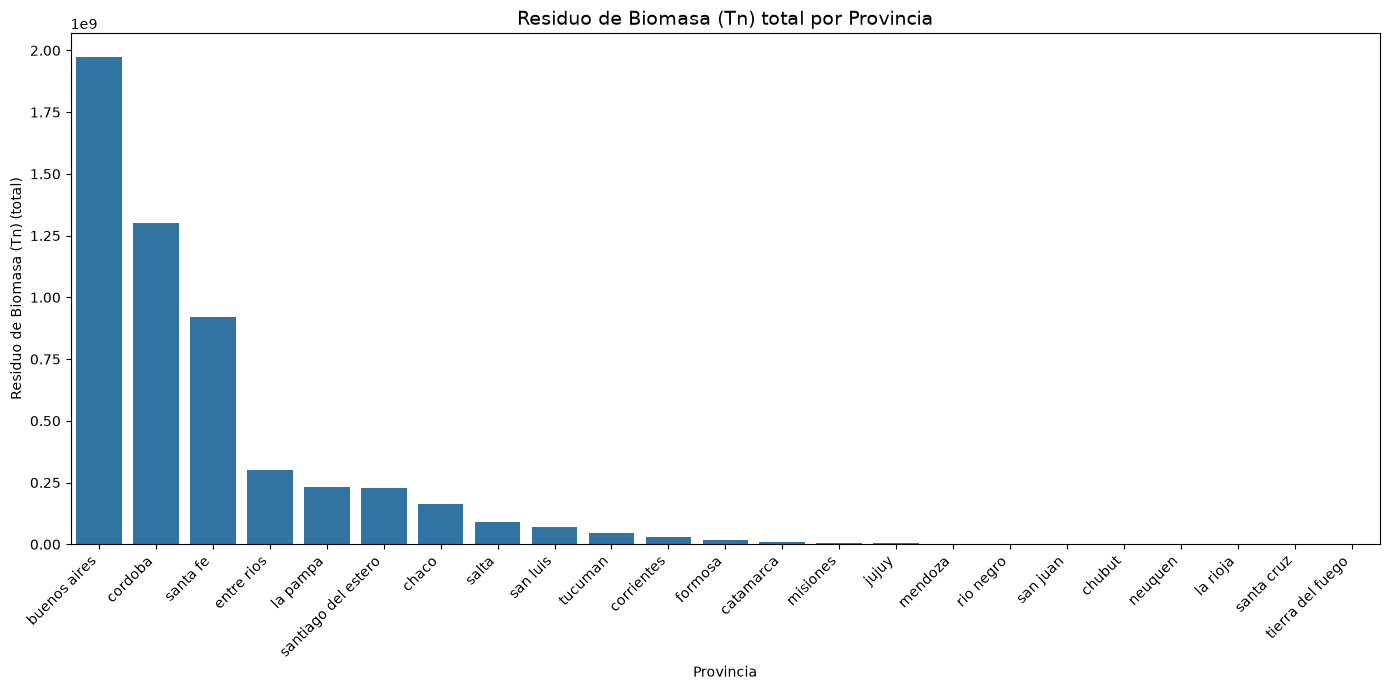

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Agregar biomasa por provincia (todos los cultivos y campañas sumados)
df_grouped = (
    df_biomasa
    .groupby(["Provincia"], as_index=False)["Residuo de Biomasa (Tn)"]
    .sum()
)

# Ordenar provincias por residuo total (descendente)
order = df_grouped.sort_values("Residuo de Biomasa (Tn)", ascending=False)["Provincia"]

# Gráfico de barras ordenado
plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_grouped,
    x="Provincia",
    y="Residuo de Biomasa (Tn)",
    order=order
)

plt.xticks(rotation=45, ha="right")
plt.title("Residuo de Biomasa (Tn) total por Provincia", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn) (total)")
plt.xlabel("Provincia")
plt.tight_layout()
plt.show()


## Mayor Produccion de Biomasa Residual por Cultivo 

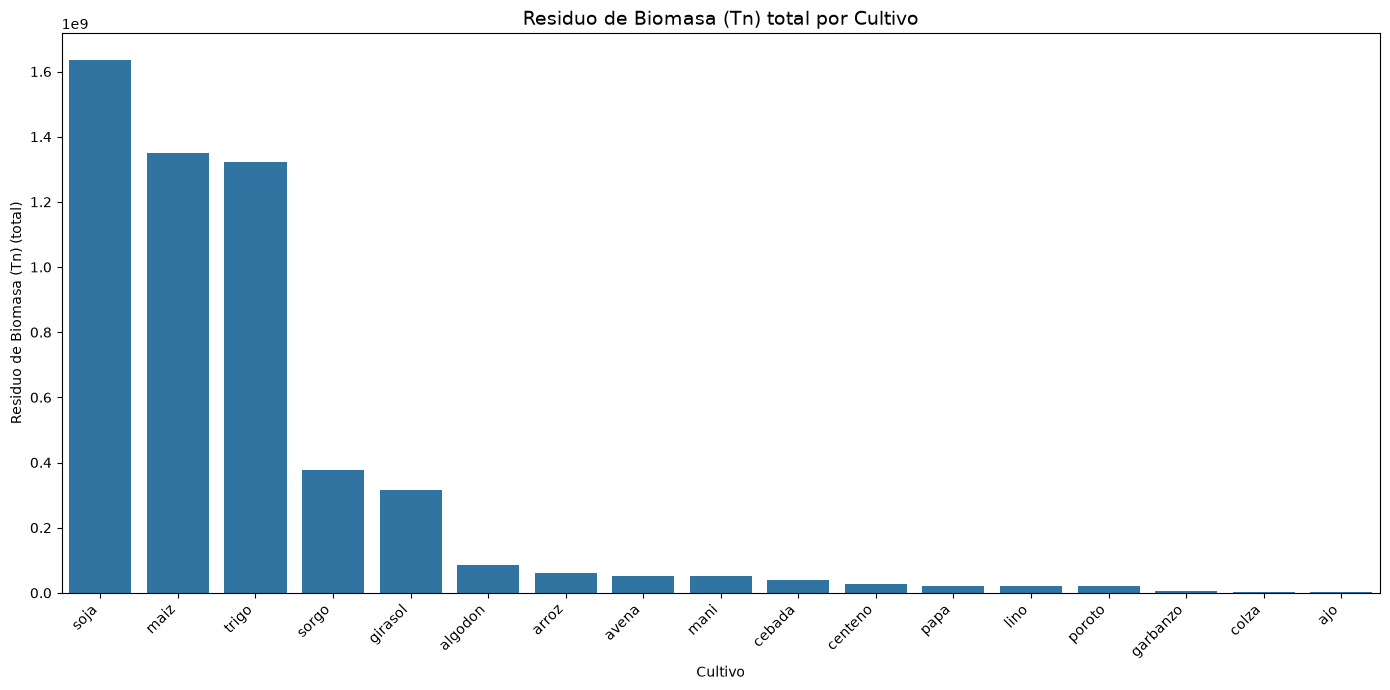

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Agregar biomasa por provincia (todos los cultivos y campañas sumados)
df_grouped = (
    df_biomasa
    .groupby(["Cultivo"], as_index=False)["Residuo de Biomasa (Tn)"]
    .sum()
)

# Ordenar provincias por residuo total (descendente)
order = df_grouped.sort_values("Residuo de Biomasa (Tn)", ascending=False)["Cultivo"]

# Gráfico de barras ordenado
plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_grouped,
    x="Cultivo",
    y="Residuo de Biomasa (Tn)",
    order=order
)

plt.xticks(rotation=45, ha="right")
plt.title("Residuo de Biomasa (Tn) total por Cultivo", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn) (total)")
plt.xlabel("Cultivo")
plt.tight_layout()
plt.show()


C:\Users\Usuario\AppData\Local\Temp\ipykernel_11584\550804834.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


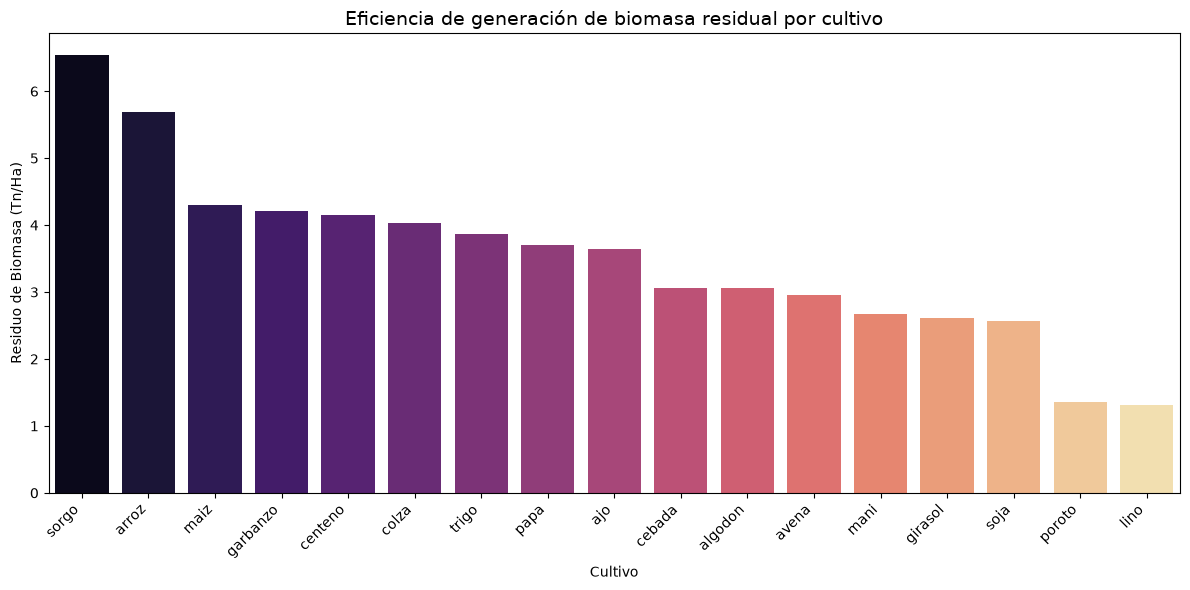

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Agrupar por cultivo y calcular promedio de residuo por hectárea
df_efficiency = (
    df_biomasa
    .groupby("Cultivo", as_index=False)["Residuo de Biomasa (Tn/Ha)"]
    .mean()
    .sort_values("Residuo de Biomasa (Tn/Ha)", ascending=False)
)


plt.figure(figsize=(12,6))
sns.barplot(
    data=df_efficiency,
    x="Cultivo",
    y="Residuo de Biomasa (Tn/Ha)",
    palette="magma"
)
plt.xticks(rotation=45, ha="right")
plt.title("Eficiencia de generación de biomasa residual por cultivo", fontsize=14)
plt.ylabel("Residuo de Biomasa (Tn/Ha)")
plt.xlabel("Cultivo")
plt.tight_layout()
plt.show()